
<div style="background-color:#dff2e1; padding:16px; border-radius:8px;">
<h1 style="margin-bottom:4px;">Industrial Data Analytics</h1>
<h2 style="margin-top:4px;">Practical Session 5 - Box Plots, Covariance, Correlation and Z-Scores</h2>
</div>

### Connection to Lecture 5

Lecture 5 develops three important statistical tools for industrial data analysis:

- **Box plots** for visualising distribution, spread and potential outliers;
- **Covariance and correlation** for investigating relationships between variables;
- **Z-scores** for expressing how far a measurement lies from the mean in standard-deviation units.

In this practical, we will apply these ideas to a 24-hour robotic-arm sensor dataset.

> Before starting, compare your Practical 4 exercise with the separate Practical 4 worked-solution notebook.



## Learning objectives

By the end of this practical you should be able to:

1. Create and interpret a box plot.
2. Calculate Q1, median, Q3 and the interquartile range.
3. Explain how box-plot whiskers and potential outliers are determined.
4. Calculate covariance manually and using pandas.
5. Explain the difference between covariance and correlation.
6. Create a scatter plot to support relationship analysis.
7. Calculate Z-scores using the population standard deviation.
8. Use Z-scores to identify statistically unusual sensor measurements.
9. Explain why a statistical outlier does not automatically mean a machine fault.
10. Produce both simple teaching figures and publication-ready versions of the same analysis.



## Figure-production standard used in this module

From this practical onward, each guided figure is shown in **two stages**:

1. **Simple teaching version** - the shortest clear code needed to create the figure.
2. **Publication-ready version** - the same information presented using a more controlled figure size, clearer typography, annotations, improved layout, and high-resolution export.

The simple version helps you learn the core plotting command. The publication-ready version demonstrates how the same analysis can be communicated in an academic report, technical document, conference paper, or professional engineering presentation.

> A publication-ready figure should still be understandable when viewed independently of the Python code. Always include clear axis labels, physical units, readable text, and an informative caption or title.



# Part 1 - Guided Practical



## 1. Re-create the robotic-arm dataset

To maintain continuity with the previous practical, we will use the same synthetic 24-hour dataset structure.

There is one reading per minute, giving **1,440 observations** for:

- Temperature in °C;
- Vibration in mm/s;
- Pressure in kPa.

A fixed random seed is used so that everyone obtains the same values.


In [1]:
# Import pandas so that we can create and analyse tabular data.
import pandas as pd

# Import NumPy so that we can generate reproducible numerical sensor data.
import numpy as np

# Import Matplotlib so that we can create statistical graphs.
import matplotlib.pyplot as plt

# Set the random seed so that the generated dataset is identical every time the notebook is run.
np.random.seed(42)

# Generate the time values from 0 to 1439 minutes.
time = np.arange(1440)

# Generate 1,440 synthetic temperature readings with a mean near 37 °C.
temperature = np.random.normal(37, 2, 1440)

# Generate 1,440 synthetic vibration readings with a mean near 0.03 mm/s.
vibration = np.random.normal(0.03, 0.01, 1440)

# Generate 1,440 synthetic pressure readings with a mean near 210 kPa.
pressure = np.random.normal(210, 15, 1440)

# Combine the four arrays into a pandas DataFrame.
data = pd.DataFrame({
    "Time": time,
    "Temperature": temperature,
    "Vibration": vibration,
    "Pressure": pressure
})

# Display the first five rows so that we can inspect the dataset.
print(data.head())


   Time  Temperature  Vibration    Pressure
0     0    37.993428   0.036629  176.426532
1     1    36.723471   0.041735  178.189498
2     2    38.295377   0.031810  200.897022
3     3    40.046060   0.017032  216.865299
4     4    36.531693   0.033997  168.787427


In [2]:
# Display the number of rows and columns.
print("DataFrame shape:", data.shape)

# Display a statistical summary of the three sensor variables.
print(data[["Temperature", "Vibration", "Pressure"]].describe())


DataFrame shape: (1440, 4)
       Temperature    Vibration     Pressure
count  1440.000000  1440.000000  1440.000000
mean     37.079688     0.030266   209.435010
std       1.974666     0.009774    15.405650
min      30.517465    -0.000195   164.885515
25%      35.725049     0.023675   199.033123
50%      37.093417     0.030035   209.468751
75%      38.341919     0.036726   219.501156
max      44.705463     0.061931   268.893566



## 2. Understanding a box plot

A box plot summarises a distribution using:

- **Q1** - 25th percentile;
- **Median (Q2)** - 50th percentile;
- **Q3** - 75th percentile;
- **IQR** - Q3 − Q1;
- **Whiskers** - extend to the most extreme observed values that remain within the 1.5 × IQR limits;
- **Potential outliers** - points beyond the whiskers.

> The maximum value is **not normally called Q4**. Standard box-plot terminology uses Q1, Q2 and Q3; the maximum is simply the maximum.


In [3]:
# Calculate the first quartile of temperature.
temperature_Q1 = data["Temperature"].quantile(0.25)

# Calculate the median temperature.
temperature_Q2 = data["Temperature"].quantile(0.50)

# Calculate the third quartile of temperature.
temperature_Q3 = data["Temperature"].quantile(0.75)

# Calculate the interquartile range.
temperature_IQR = temperature_Q3 - temperature_Q1

# Calculate the lower 1.5 × IQR fence.
temperature_lower_fence = temperature_Q1 - 1.5 * temperature_IQR

# Calculate the upper 1.5 × IQR fence.
temperature_upper_fence = temperature_Q3 + 1.5 * temperature_IQR

# Display Q1.
print(f"Temperature Q1: {temperature_Q1:.3f} °C")

# Display the median.
print(f"Temperature median: {temperature_Q2:.3f} °C")

# Display Q3.
print(f"Temperature Q3: {temperature_Q3:.3f} °C")

# Display the IQR.
print(f"Temperature IQR: {temperature_IQR:.3f} °C")

# Display the lower fence.
print(f"Lower fence: {temperature_lower_fence:.3f} °C")

# Display the upper fence.
print(f"Upper fence: {temperature_upper_fence:.3f} °C")


Temperature Q1: 35.725 °C
Temperature median: 37.093 °C
Temperature Q3: 38.342 °C
Temperature IQR: 2.617 °C
Lower fence: 31.800 °C
Upper fence: 42.267 °C


In [4]:
# Create a Boolean condition for temperatures below the lower fence.
temperature_below_fence = data["Temperature"] < temperature_lower_fence

# Create a Boolean condition for temperatures above the upper fence.
temperature_above_fence = data["Temperature"] > temperature_upper_fence

# Select all rows that satisfy either outlier condition.
temperature_outliers = data[temperature_below_fence | temperature_above_fence]

# Display the number of potential temperature outliers.
print("Number of potential temperature outliers:", len(temperature_outliers))

# Display the rows containing potential temperature outliers.
print(temperature_outliers)


Number of potential temperature outliers: 9
      Time  Temperature  Vibration    Pressure
74      74    31.760510   0.029173  195.766252
179    179    42.440338   0.041484  204.064789
209    209    44.705463   0.055896  212.153819
262    262    30.517465   0.036347  208.513585
478    478    43.157762   0.028319  216.872522
646    646    31.606227   0.024919  207.030934
668    668    31.698060   0.026714  193.326296
1061  1061    31.302915   0.039682  228.453333
1101  1101    31.207489   0.017415  234.609218


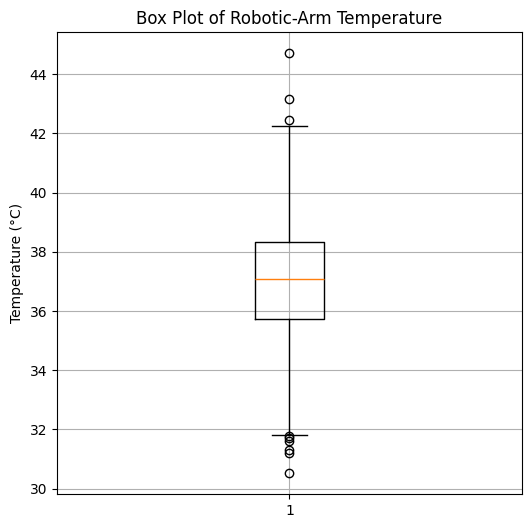

In [5]:
# Create a new figure for the temperature box plot.
plt.figure(figsize=(6, 6))

# Create a vertical box plot using the temperature measurements.
plt.boxplot(data["Temperature"])

# Label the vertical axis and include the measurement unit.
plt.ylabel("Temperature (°C)")

# Add a meaningful title.
plt.title("Box Plot of Robotic-Arm Temperature")

# Add grid lines to make the plot easier to read.
plt.grid(True)

# Display the completed box plot.
plt.show()



### Publication-ready version of the same box plot

The next cell presents the same temperature distribution, but adds controlled figure dimensions, more readable text, direct statistical annotations, cleaner axes, and a high-resolution export command.


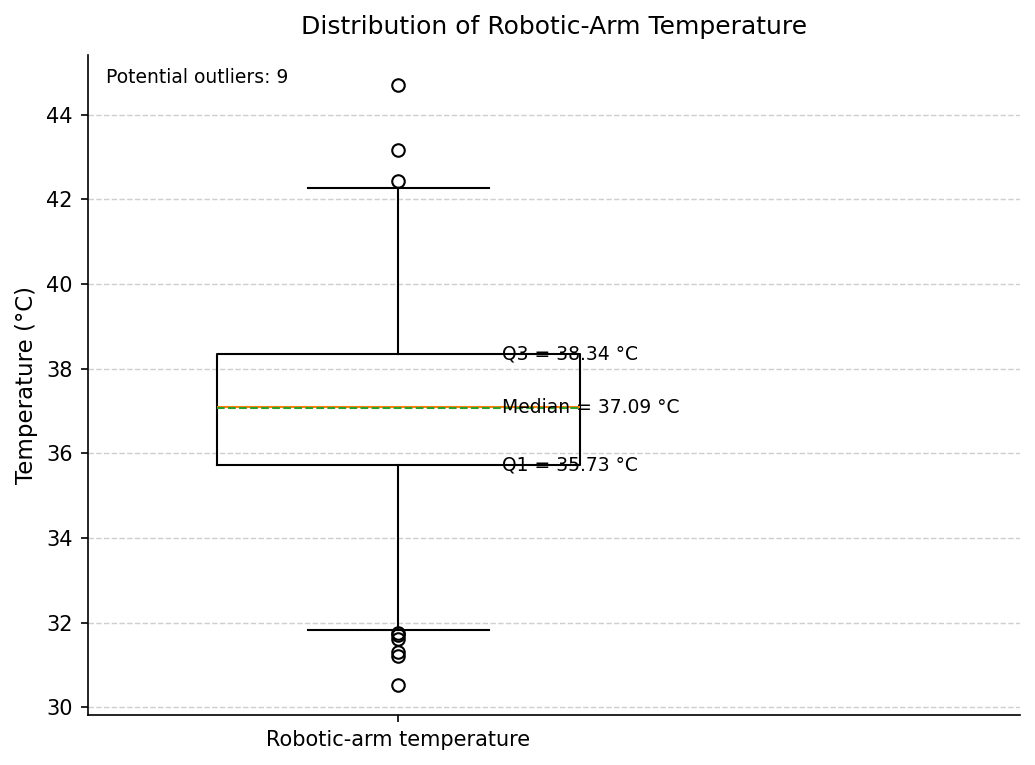

In [6]:
# Create a figure and an axes object so that we can control each formatting element directly.
fig, ax = plt.subplots(figsize=(7.0, 5.2), dpi=150)

# Draw the same temperature box plot on the selected axes.
ax.boxplot(data["Temperature"], widths=0.35, showmeans=True, meanline=True)

# Add a descriptive vertical-axis label and include the physical unit.
ax.set_ylabel("Temperature (°C)", fontsize=11)

# Replace the default x-axis number with a meaningful category label.
ax.set_xticks([1])

# Label the single box so that the figure can be understood without reading the code.
ax.set_xticklabels(["Robotic-arm temperature"], fontsize=10)

# Add a concise professional title.
ax.set_title("Distribution of Robotic-Arm Temperature", fontsize=12, pad=10)

# Increase the tick-label size so that values remain readable in a report or paper.
ax.tick_params(axis="y", labelsize=10)

# Add horizontal grid lines to support visual comparison of values.
ax.grid(axis="y", linestyle="--", linewidth=0.7, alpha=0.6)

# Remove the top border to reduce unnecessary visual clutter.
ax.spines["top"].set_visible(False)

# Remove the right border to reduce unnecessary visual clutter.
ax.spines["right"].set_visible(False)

# Extend the horizontal plotting area to leave room for statistical annotations.
ax.set_xlim(0.70, 1.60)

# Annotate the first quartile directly on the figure.
ax.text(1.10, temperature_Q1, f"Q1 = {temperature_Q1:.2f} °C", va="center", fontsize=9)

# Annotate the median directly on the figure.
ax.text(1.10, temperature_Q2, f"Median = {temperature_Q2:.2f} °C", va="center", fontsize=9)

# Annotate the third quartile directly on the figure.
ax.text(1.10, temperature_Q3, f"Q3 = {temperature_Q3:.2f} °C", va="center", fontsize=9)

# Add the number of potential outliers as a compact figure annotation.
ax.text(
    0.02,
    0.98,
    f"Potential outliers: {len(temperature_outliers)}",
    transform=ax.transAxes,
    va="top",
    fontsize=9
)

# Adjust the spacing so that labels and annotations are not clipped.
fig.tight_layout()

# Save a high-resolution copy suitable for reports, posters, or publication workflows.
fig.savefig("temperature_boxplot_publication.png", dpi=300, bbox_inches="tight")

# Display the publication-ready figure in the notebook.
plt.show()



### Interpreting the box plot

The box contains the central 50% of the temperature measurements. The line inside the box is the median. Points beyond the whiskers are potential statistical outliers.

In an industrial context, such points may represent:

- a genuine unusual operating condition;
- a transient event;
- a sensor problem;
- a recording error;
- or a valid rare observation.

They should therefore be **investigated**, not automatically deleted.



## 3. Covariance - direction of a relationship

Covariance helps determine whether two variables tend to move in the same or opposite directions.

- Positive covariance: both tend to increase together.
- Negative covariance: one tends to increase while the other tends to decrease.
- Covariance close to zero: little evidence of a linear relationship.

Lecture 5 uses the **sample covariance** formula, which divides by $n-1$. We will first reproduce that calculation manually.


In [7]:
# Calculate the mean temperature.
mean_temperature = data["Temperature"].mean()

# Calculate the mean vibration.
mean_vibration = data["Vibration"].mean()

# Calculate each temperature deviation from the temperature mean.
temperature_deviation = data["Temperature"] - mean_temperature

# Calculate each vibration deviation from the vibration mean.
vibration_deviation = data["Vibration"] - mean_vibration

# Multiply the paired deviations.
deviation_products = temperature_deviation * vibration_deviation

# Add all paired deviation products.
sum_deviation_products = deviation_products.sum()

# Count the number of paired observations.
number_of_readings = len(data)

# Divide by n - 1 to calculate the sample covariance.
manual_covariance = sum_deviation_products / (number_of_readings - 1)

# Display the manually calculated covariance.
print(f"Manual Temperature-Vibration covariance: {manual_covariance:.8f}")


Manual Temperature-Vibration covariance: -0.00014598


In [8]:
# Ask pandas to calculate the sample covariance directly.
pandas_covariance = data["Temperature"].cov(data["Vibration"])

# Display the pandas covariance result.
print(f"Pandas Temperature-Vibration covariance: {pandas_covariance:.8f}")

# Display the difference between the manual and pandas results.
print(f"Difference between methods: {manual_covariance - pandas_covariance:.12f}")


Pandas Temperature-Vibration covariance: -0.00014598
Difference between methods: 0.000000000000



The manual result and the pandas result should agree apart from tiny floating-point rounding effects.

### Limitation of covariance

The numerical size of covariance depends on the units and scales of the two variables. This means that the magnitude of covariance is not easy to compare across different pairs of variables.



## 4. Correlation - a standardised relationship measure

Correlation is closely related to covariance but is standardised to lie between **−1 and +1**.

- +1 = perfect positive linear relationship;
- 0 = no linear relationship;
- −1 = perfect negative linear relationship.

This makes correlation easier to interpret and compare.


In [9]:
# Calculate the Pearson correlation coefficient between Temperature and Vibration.
temperature_vibration_correlation = data["Temperature"].corr(data["Vibration"])

# Display the correlation coefficient.
print(f"Temperature-Vibration correlation: {temperature_vibration_correlation:.4f}")


Temperature-Vibration correlation: -0.0076


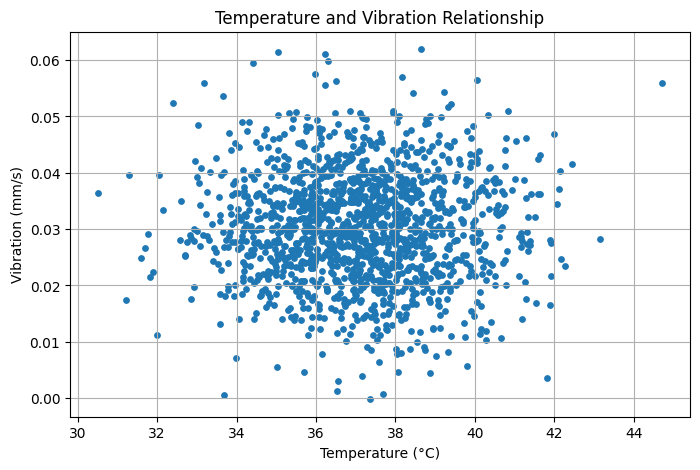

In [10]:
# Create a new figure for the scatter plot.
plt.figure(figsize=(8, 5))

# Plot each temperature-vibration pair as one point.
plt.scatter(data["Temperature"], data["Vibration"], s=15)

# Label the horizontal axis.
plt.xlabel("Temperature (°C)")

# Label the vertical axis.
plt.ylabel("Vibration (mm/s)")

# Add a meaningful title.
plt.title("Temperature and Vibration Relationship")

# Add grid lines to aid reading.
plt.grid(True)

# Display the scatter plot.
plt.show()



### Publication-ready version of the same scatter plot

This version keeps the same Temperature-Vibration relationship but adds a fitted visual trend, a correlation annotation, controlled typography, cleaner axes, and high-resolution export.


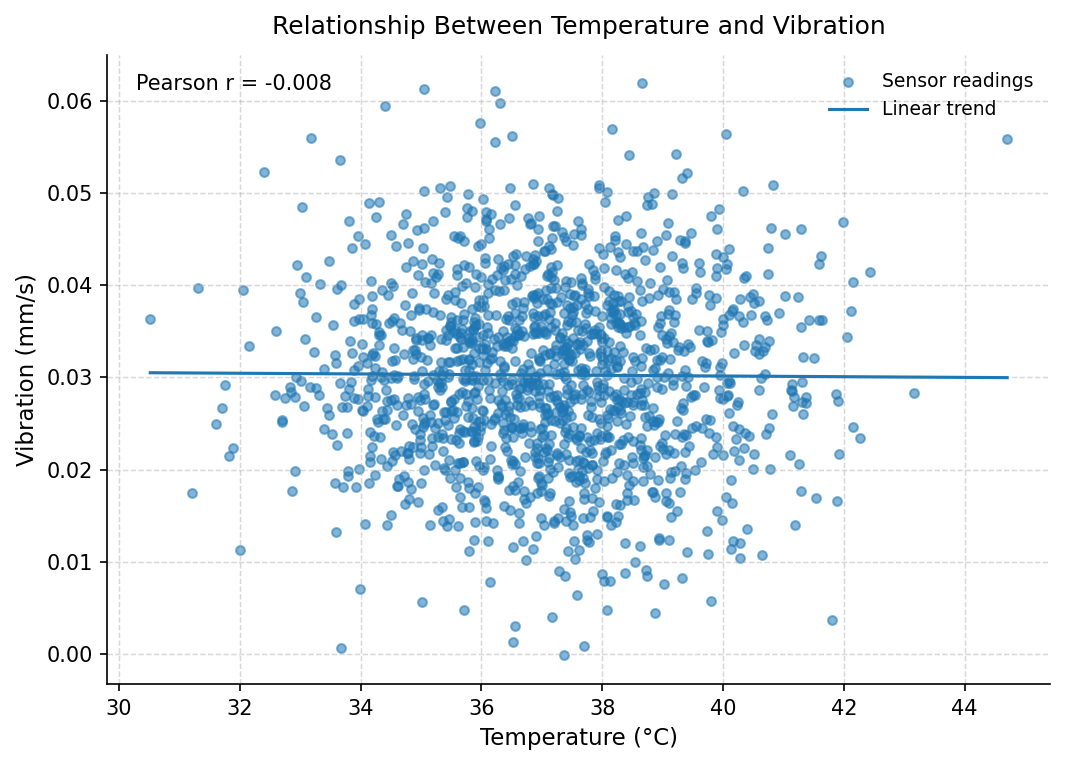

In [11]:
# Create a figure and axes object with dimensions appropriate for a report or paper.
fig, ax = plt.subplots(figsize=(7.2, 5.2), dpi=150)

# Plot the individual Temperature-Vibration observations.
ax.scatter(data["Temperature"], data["Vibration"], s=18, alpha=0.55, label="Sensor readings")

# Calculate the coefficients of a straight-line trend fitted to the plotted data.
trend_coefficients = np.polyfit(data["Temperature"], data["Vibration"], 1)

# Create evenly spaced temperature values covering the observed data range.
trend_temperature = np.linspace(data["Temperature"].min(), data["Temperature"].max(), 200)

# Calculate the fitted vibration value at every trend-line temperature.
trend_vibration = np.polyval(trend_coefficients, trend_temperature)

# Plot the fitted linear trend to help the reader judge the direction of the relationship.
ax.plot(trend_temperature, trend_vibration, linewidth=1.5, label="Linear trend")

# Label the horizontal axis and include the physical unit.
ax.set_xlabel("Temperature (°C)", fontsize=11)

# Label the vertical axis and include the physical unit.
ax.set_ylabel("Vibration (mm/s)", fontsize=11)

# Add a concise title describing the relationship shown.
ax.set_title("Relationship Between Temperature and Vibration", fontsize=12, pad=10)

# Increase the tick-label size for readability.
ax.tick_params(axis="both", labelsize=10)

# Add a light grid so that values can be read more easily.
ax.grid(True, linestyle="--", linewidth=0.7, alpha=0.5)

# Remove the top border to create a cleaner professional appearance.
ax.spines["top"].set_visible(False)

# Remove the right border to create a cleaner professional appearance.
ax.spines["right"].set_visible(False)

# Display the Pearson correlation coefficient directly on the figure.
ax.text(
    0.03,
    0.97,
    f"Pearson r = {temperature_vibration_correlation:.3f}",
    transform=ax.transAxes,
    va="top",
    fontsize=10
)

# Add a legend identifying the observations and fitted trend.
ax.legend(frameon=False, fontsize=9)

# Adjust spacing so that all labels fit cleanly inside the saved figure.
fig.tight_layout()

# Save the figure at high resolution for academic or professional use.
fig.savefig("temperature_vibration_scatter_publication.png", dpi=300, bbox_inches="tight")

# Display the publication-ready figure.
plt.show()



### Interpretation

For this synthetic dataset, the correlation is very close to zero and the scatter plot shows no clear linear trend.

A crucial point is that **correlation does not prove causation**. Even a strong correlation would require engineering investigation before concluding that one variable causes changes in another.



## 5. Z-scores

A Z-score expresses a measurement's position relative to the mean:

$$
Z = \frac{X-\bar{X}}{\sigma}
$$

A Z-score of:

- 0 means the reading is at the mean;
- +2 means two standard deviations above the mean;
- −2 means two standard deviations below the mean.

Lecture 5 uses $\sigma$, so we will calculate the **population standard deviation** using `ddof=0`.


In [12]:
# Calculate the mean temperature.
temperature_mean = data["Temperature"].mean()

# Calculate the population standard deviation of temperature.
temperature_std = data["Temperature"].std(ddof=0)

# Calculate the Z-score for every temperature reading.
data["Temperature_Z"] = (data["Temperature"] - temperature_mean) / temperature_std

# Display the first five temperature readings and their Z-scores.
print(data[["Temperature", "Temperature_Z"]].head())


   Temperature  Temperature_Z
0    37.993428       0.462892
1    36.723471      -0.180456
2    38.295377       0.615857
3    40.046060       1.502736
4    36.531693      -0.277609


In [13]:
# Create a Boolean condition for readings more than three standard deviations from the mean.
extreme_temperature_condition = data["Temperature_Z"].abs() > 3

# Select the rows satisfying the condition.
extreme_temperature_z_scores = data[extreme_temperature_condition]

# Display the number of temperature readings with absolute Z-score greater than 3.
print("Number of |Z| > 3 temperature readings:", len(extreme_temperature_z_scores))

# Display the unusual readings.
print(extreme_temperature_z_scores[["Time", "Temperature", "Temperature_Z"]])


Number of |Z| > 3 temperature readings: 3
     Time  Temperature  Temperature_Z
209   209    44.705463       3.863147
262   262    30.517465      -3.324362
478   478    43.157762       3.079096



### Interpreting the threshold

A common rule treats $|Z| > 3$ as statistically unusual. This is useful for screening large datasets, but the same engineering caution applies:

**statistically unusual does not automatically mean faulty or unsafe.**


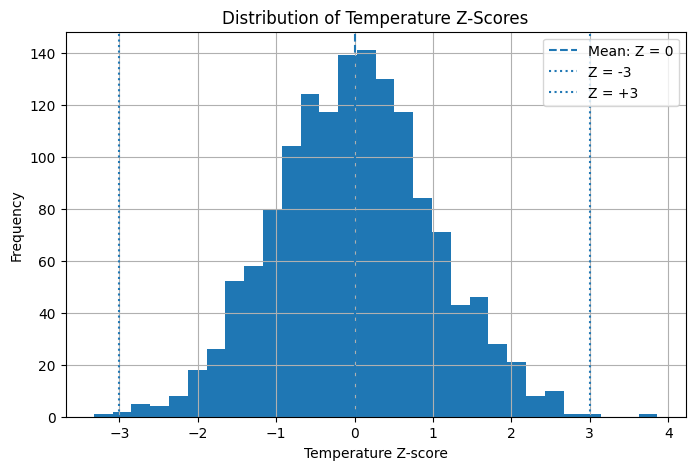

In [14]:
# Create a new figure for the temperature Z-score histogram.
plt.figure(figsize=(8, 5))

# Plot the distribution of temperature Z-scores.
plt.hist(data["Temperature_Z"], bins=30)

# Draw a vertical reference line at Z = 0.
plt.axvline(0, linestyle="--", label="Mean: Z = 0")

# Draw a vertical reference line at Z = -3.
plt.axvline(-3, linestyle=":", label="Z = -3")

# Draw a vertical reference line at Z = 3.
plt.axvline(3, linestyle=":", label="Z = +3")

# Label the horizontal axis.
plt.xlabel("Temperature Z-score")

# Label the vertical axis.
plt.ylabel("Frequency")

# Add a meaningful title.
plt.title("Distribution of Temperature Z-Scores")

# Display the reference-line labels.
plt.legend()

# Add grid lines.
plt.grid(True)

# Display the histogram.
plt.show()



### Publication-ready version of the same Z-score histogram

This version retains the same Z-score distribution but improves the presentation with controlled typography, reference-line annotations, an explicit count of statistically unusual readings, and high-resolution export.


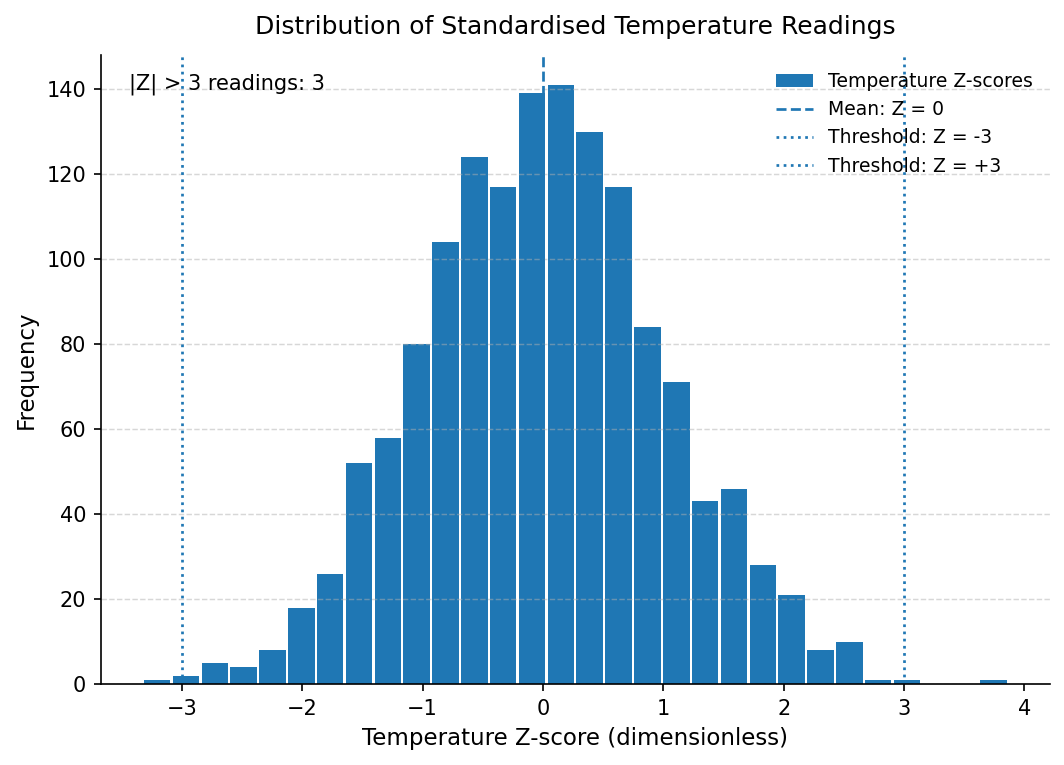

In [15]:
# Create a figure and axes object with a publication-friendly aspect ratio.
fig, ax = plt.subplots(figsize=(7.2, 5.2), dpi=150)

# Plot the Temperature Z-score distribution using 30 bins.
ax.hist(data["Temperature_Z"], bins=30, rwidth=0.92, label="Temperature Z-scores")

# Draw a dashed reference line at the mean, where Z equals zero.
ax.axvline(0, linestyle="--", linewidth=1.3, label="Mean: Z = 0")

# Draw a dotted reference line at the lower unusual-value threshold.
ax.axvline(-3, linestyle=":", linewidth=1.3, label="Threshold: Z = -3")

# Draw a dotted reference line at the upper unusual-value threshold.
ax.axvline(3, linestyle=":", linewidth=1.3, label="Threshold: Z = +3")

# Label the horizontal axis; a Z-score is dimensionless.
ax.set_xlabel("Temperature Z-score (dimensionless)", fontsize=11)

# Label the vertical axis.
ax.set_ylabel("Frequency", fontsize=11)

# Add a concise title describing the plotted distribution.
ax.set_title("Distribution of Standardised Temperature Readings", fontsize=12, pad=10)

# Increase tick-label size for readability.
ax.tick_params(axis="both", labelsize=10)

# Add a light horizontal grid to support reading the frequency scale.
ax.grid(axis="y", linestyle="--", linewidth=0.7, alpha=0.5)

# Remove the top border to reduce visual clutter.
ax.spines["top"].set_visible(False)

# Remove the right border to reduce visual clutter.
ax.spines["right"].set_visible(False)

# Annotate the number of readings beyond the ±3 threshold.
ax.text(
    0.03,
    0.97,
    f"|Z| > 3 readings: {len(extreme_temperature_z_scores)}",
    transform=ax.transAxes,
    va="top",
    fontsize=10
)

# Add a legend identifying the distribution and reference thresholds.
ax.legend(frameon=False, fontsize=9)

# Adjust spacing so the figure is not clipped when saved.
fig.tight_layout()

# Save a high-resolution version suitable for a report or publication.
fig.savefig("temperature_zscore_histogram_publication.png", dpi=300, bbox_inches="tight")

# Display the publication-ready histogram.
plt.show()



## 6. Why Z-scores are useful across sensors

Temperature, vibration and pressure have different units, so their raw values cannot be compared directly.

Z-scores convert them to a common standard-deviation scale. A value of $Z=2.5$ has the same statistical meaning regardless of whether it came from °C, mm/s or kPa.


In [16]:
# Calculate the temperature population standard deviation.
temperature_population_std = data["Temperature"].std(ddof=0)

# Calculate the vibration population standard deviation.
vibration_population_std = data["Vibration"].std(ddof=0)

# Calculate the pressure population standard deviation.
pressure_population_std = data["Pressure"].std(ddof=0)

# Calculate a Z-score for every temperature reading.
data["Temperature_Z"] = (data["Temperature"] - data["Temperature"].mean()) / temperature_population_std

# Calculate a Z-score for every vibration reading.
data["Vibration_Z"] = (data["Vibration"] - data["Vibration"].mean()) / vibration_population_std

# Calculate a Z-score for every pressure reading.
data["Pressure_Z"] = (data["Pressure"] - data["Pressure"].mean()) / pressure_population_std

# Display the first five rows of the three standardised sensor variables.
print(data[["Temperature_Z", "Vibration_Z", "Pressure_Z"]].head())


   Temperature_Z  Vibration_Z  Pressure_Z
0       0.462892     0.651233   -2.143366
1      -0.180456     1.173791   -2.028890
2       0.615857     0.158081   -0.554404
3       1.502736    -1.354405    0.482477
4      -0.277609     0.381872   -2.639402



# Part 2 - Student Exercise

## Statistical monitoring of robotic-arm sensor data

Use the `data` DataFrame created in Part 1.

You will now apply the same statistical ideas to different sensor variables.



### Task 1 - Pressure box plot and outliers

For **Pressure**:

1. Calculate Q1, median and Q3.
2. Calculate the IQR.
3. Calculate the lower and upper 1.5 × IQR fences.
4. Identify the potential pressure outliers.
5. Print the number of potential outliers.
6. Create a **simple** box plot with an appropriate title and unit.
7. Create a **second, publication-ready version** of the same box plot. Use a `fig, ax = plt.subplots(...)` structure, readable font sizes, a clean grid, clear units, at least one useful statistical annotation, `tight_layout()`, and save it at 300 dpi.

**Hint:** Adapt the temperature example from Part 1.


In [17]:
# Write your code for Task 1 below.




### Task 2 - Covariance between Pressure and Vibration

Calculate the **sample covariance** between Pressure and Vibration in two ways:

1. manually using deviations from the means and division by $n-1$;
2. using pandas `.cov()`.

Confirm that the two results agree.

**Hint:** Follow the Temperature-Vibration calculation from Part 1.


In [18]:
# Write your code for Task 2 below.




### Task 3 - Correlation and scatter plot

1. Calculate the correlation between Pressure and Vibration.
2. Create a **simple** scatter plot of Pressure against Vibration.
3. Create a **second, publication-ready version** of the same scatter plot with controlled figure size, clear units, readable font sizes, a clean grid, the correlation coefficient annotated on the figure, `tight_layout()`, and a 300 dpi saved copy.
4. State whether the linear relationship is:
   - positive or negative;
   - weak or strong.

**Hint:** A correlation close to zero indicates little linear relationship.


In [19]:
# Write your code for Task 3 below.




**Write your interpretation here:**

-



### Task 4 - Vibration Z-scores

1. Calculate the mean Vibration.
2. Calculate its population standard deviation using `ddof=0`.
3. Calculate the Z-score of every vibration reading.
4. Store the result in a new column called `Vibration_Z_Exercise`.
5. Identify readings where $|Z| > 3$.
6. Print the number of unusual readings and display them.

**Hint:** Use `.abs()` when testing both positive and negative Z-scores.


In [20]:
# Write your code for Task 4 below.




### Task 5 - Compare unusualness across different sensors

Find:

- the row with the largest absolute Temperature Z-score;
- the row with the largest absolute Vibration Z-score;
- the row with the largest absolute Pressure Z-score.

For each one, print:

- Time;
- original sensor reading;
- Z-score.

Then answer:

**Which sensor contains the most statistically extreme individual reading in this dataset?**

**Hint:** `.abs().idxmax()` can identify the row containing the largest absolute Z-score.


In [21]:
# Write your code for Task 5 below.




**Write your answer here:**

-



### Task 6 - Engineering interpretation

Answer the following in your own words:

1. What information does a box plot provide that a mean alone does not?
2. Why does covariance indicate direction but not provide an easily comparable measure of relationship strength?
3. Why is correlation easier to compare across different variable pairs?
4. What does a Z-score of −2.5 mean?
5. Why should a reading with $|Z| > 3$ be investigated rather than automatically deleted?
6. Why does correlation not prove causation?

**Write your answers here:**

1.  
2.  
3.  
4.  
5.  
6.  



## Optional challenge - Compare two outlier methods

For **Vibration**, compare:

- the **1.5 × IQR box-plot rule**;
- the **|Z| > 3 rule**.

Calculate the number of readings identified by each method.

Then determine:

- which rows are identified by both methods;
- whether the two methods produce exactly the same result.

### Reflection

Why might two valid statistical outlier methods identify different observations?


In [22]:
# Write your optional challenge code below.




# End-of-practical reflection

Before finishing, make sure you can explain:

- the components of a box plot;
- why the whiskers do not necessarily extend to the minimum and maximum;
- the meaning of positive, negative and near-zero covariance;
- the difference between covariance and correlation;
- the meaning of a positive or negative Z-score;
- why standardisation allows variables with different units to be compared;
- why statistical outliers need engineering interpretation.

### Save your work

Save your completed notebook. The separate worked solution can be released in the following session for comparison.
